In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':20})
import os
from scipy.io import loadmat
import scipy as sp

import sys
sys.path.append('../src/')

from Ophelia_ODE_evaluation import LatentAssemblyModel, load_venturelli_arrays, train_model, evaluate_predictions
from SerialDilutionModels import LatentAssemblyNeuralODE
from MeOH_cross_host_transfer import load_data_filtered
import torch
import copy
from glob import glob

# Data exploration

In [8]:
def extract_rumen_trajectories(metadata_df, species_df, save_path=None):
    """
    Parses the Rumen enrichment metadata and species counts to extract chronological 
    sequences of relative abundances for every unique experimental condition.
    
    Returns:
        dict: Keys are unique condition tuples (Origin, Substrate, Pressure).
              Values are chronologically ordered PyTorch tensors of relative abundances 
              (Shape: Timepoints x Species).
        list: Strains/Taxonomy names in the correct index order.
    """
    # 0. Process Species Data (Normalize to relative abundance)
    # Find the taxonomy column (case-insensitive search)
    tax_col = [c for c in species_df.columns if 'tax' in c.lower()][0]
    
    # Set taxonomy as index and ensure all data is numeric
    species_counts = species_df.set_index(tax_col).apply(pd.to_numeric, errors='coerce').fillna(0)
    
    # Normalize columns (samples) so they sum to 1
    rel_abund = species_counts.div(species_counts.sum(axis=0), axis=1)
    rel_abund = rel_abund.fillna(0.0) # Handle completely empty samples if any
    strains = rel_abund.index.tolist()
    
    # 1. Clean up DataFrame and skip missing Transfers (Inoculum/T0)
    df = metadata_df.copy()
    
    substrate_col = 'Methanogenic  substrate'
    pressure_col = 'Hydrogen partial pressure (psi)'
    origin_col = 'Rumen sample origin'
    
    # Drop any rows where 'Transfer' is NaN (the Inoculum) or explicitly 'T0'
    df = df.dropna(subset=['Transfer'])
    df = df[df['Transfer'] != 'T0']
    
    # 2. Group by Unique Conditions (Trajectories now start at T1)
    trajectories = {}
    grouped = df.groupby([origin_col, substrate_col, pressure_col], dropna=False)
    
    for condition_tuple, group_data in grouped:
        origin, substrate, pressure = condition_tuple
        
        # Sort the group by Transfer (T1, T2, T3, etc.)
        group_data = group_data.copy()
        group_data['T_num'] = group_data['Transfer'].str.extract(r'(\d+)').astype(int)
        sorted_group = group_data.sort_values('T_num')
        
        # Extract the sequence of treated Sample IDs (T1 onwards)
        sequence = sorted_group['Sample ID'].tolist()
        
        # 3. Map Sample IDs to Relative Abundance vectors
        valid_sequence = []
        for sample_id in sequence:
            if sample_id in rel_abund.columns:
                valid_sequence.append(rel_abund[sample_id].values)
            else:
                print(f"Warning: Sample ID '{sample_id}' not found in species data. Skipping.")
        
        # Save if we have at least 2 points (e.g. T1 -> T2)
        if len(valid_sequence) > 1:
            # Convert to PyTorch Tensor of shape (Time_steps, Num_species)
            trajectories[condition_tuple] = torch.tensor(np.array(valid_sequence), dtype=torch.float32)
        
    # 4. Save outputs
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        torch.save({'trajectories': trajectories, 'strains': strains}, save_path)
        print(f"Saved extracted relative abundance trajectories to '{save_path}'")
        
    return trajectories, strains

In [3]:
data_dir = '../Data/'

species_data_path = os.path.join(data_dir, 'species.txt')

In [4]:
species_data = pd.read_csv(species_data_path, sep='\t')
species_data = species_data.rename(columns={'Unnamed: 0': 'taxonomy'})
species_data.head()

,taxonomy,BE-1010-T1-M05,BE-1010-T1-M30,BE-1010-T1-N05,BE-1010-T1-N30,BE-1010-T1-T05,BE-1010-T1-T30,BE-1010-T2-M05,BE-1010-T2-M30,BE-1010-T2-N05,...,BE-1011-T5-N05,BE-1011-T5-N30,BE-1011-T5-T05,BE-1011-T5-T30,BE-1011-T6-M05,BE-1011-T6-M30,BE-1011-T6-N05,BE-1011-T6-N30,BE-1011-T6-T05,BE-1011-T6-T30
0,Archaea|Euryarchaeota|Methanomicrobia|Methanom...,0.414132,0.381383,0.281651,0.210417,0.007401,0.037288,0.041557,0.177807,0.006092,...,0.065360,0.423262,0.004218,0.000031,0.000000,0.009909,0.418829,0.546549,0.215175,0.000000
1,Bacteria|Synergistetes|Synergistia|Synergistal...,0.090022,0.101543,0.051995,0.095122,0.075380,0.071628,0.075582,0.044339,0.045201,...,0.020132,0.013392,0.034567,0.019355,0.008291,0.004620,0.013668,0.005357,0.018427,0.015606
2,Bacteria|Firmicutes|Bacilli|Lactobacillales|St...,0.072366,0.039241,0.076887,0.000067,0.108731,0.090901,0.052932,0.043863,0.113838,...,0.022593,0.025737,0.070785,0.011048,0.002917,0.004432,0.006991,0.008627,0.025881,0.094910
3,Bacteria|Bacteroidetes|Bacteroidia|Bacteroidal...,0.044427,0.014155,0.017633,0.009081,0.012106,0.006673,0.037508,0.016198,0.021384,...,0.040906,0.014481,0.009235,0.028010,0.020659,0.008922,0.065792,0.009500,0.013495,0.015160
4,Bacteria|Synergistetes|Synergistia|Synergistal...,0.025220,0.027153,0.015551,0.029526,0.022796,0.022021,0.023352,0.013682,0.013627,...,0.014326,0.005679,0.023916,0.015235,0.003579,0.002414,0.008760,0.003341,0.014624,0.008886


In [5]:
rumen_enrichment_metadata_path = os.path.join(data_dir, 'Rumen enrichment metadata.xlsx')
rumen_enrichment_metadata = pd.read_excel(rumen_enrichment_metadata_path)
rumen_enrichment_metadata = rumen_enrichment_metadata.drop(columns=['Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7'])
rumen_enrichment_metadata.head()

,Sample ID,Rumen sample origin,Transfer,Methanogenic substrate,Hydrogen partial pressure (psi)
0,BE-1010-T1-T05,OSU,T1,H2:CO2 + TMA,5.0
1,BE-1011-T1-N30,BRRS,T1,H2:CO2,30.0
2,BE-1010-T1-N05,OSU,T1,H2:CO2,5.0
3,BE-1011-T1-M30,BRRS,T1,H2:CO2 + MeOH,30.0
4,BE-1011-T1-T30,BRRS,T1,H2:CO2 + TMA,30.0


In [11]:
condition_trajectories, strain_list = extract_rumen_trajectories(rumen_enrichment_metadata, species_data, save_path='../Data/German_processed_data.pt')

Saved extracted relative abundance trajectories to '../Data/German_processed_data.pt'


In [19]:
for cond, seq_tensor in condition_trajectories.items():
    print(f"Condition: {cond}")
    # print(f"Shape (Timepoints, Species): {seq_tensor.shape}")
    # print(f"Sequence Tensor:\n{seq_tensor}")

Condition: ('BRRS', 'H2:CO2', np.float64(5.0))
Condition: ('BRRS', 'H2:CO2', np.float64(30.0))
Condition: ('BRRS', 'H2:CO2 + MeOH', np.float64(5.0))
Condition: ('BRRS', 'H2:CO2 + MeOH', np.float64(30.0))
Condition: ('BRRS', 'H2:CO2 + TMA', np.float64(5.0))
Condition: ('BRRS', 'H2:CO2 + TMA', np.float64(30.0))
Condition: ('OSU', 'H2:CO2', np.float64(5.0))
Condition: ('OSU', 'H2:CO2', np.float64(30.0))
Condition: ('OSU', 'H2:CO2 + MeOH', np.float64(5.0))
Condition: ('OSU', 'H2:CO2 + MeOH', np.float64(30.0))
Condition: ('OSU', 'H2:CO2 + TMA', np.float64(5.0))
Condition: ('OSU', 'H2:CO2 + TMA', np.float64(30.0))


In [15]:
len(strain_list)

751

In [16]:
len(condition_trajectories)

12

# Model steady state exploration

In [64]:
def simulate_to_steady_state(model, x_0, condition_idx, max_passages=1000, tol=1e-6):
    """
    Simulates the ODE model passage-by-passage until the relative abundances reach steady state.
    """
    entropy_list = [sp.stats.entropy(x_0)]
    with torch.no_grad():
        x_T = x_0.clone().unsqueeze(0) if x_0.dim() == 1 else x_0.clone()
        c_tensor = torch.tensor([condition_idx], dtype=torch.long)

        for passage in range(max_passages):
            # Model returns: log_x_T_plus_1, x_T_plus_1, N_final, R_final
            _, x_T_plus_1, _, _ = model(x_T, c_tensor)
            entropy = sp.stats.entropy(x_T_plus_1.squeeze(0))
            entropy_list.append(entropy)
            max_diff = torch.max(torch.abs(x_T_plus_1 - x_T))
            if max_diff < tol:
                print(f"Converged to steady state after {passage + 1} passages.")
                return x_T_plus_1.squeeze(0), passage + 1, entropy_list

            x_T = x_T_plus_1

        print(f"Warning: Reached max passages ({max_passages}) without converging.")
        return x_T.squeeze(0), max_passages, entropy_list

In [13]:
data_path = '../Data/German_processed_data.pt'
# These test keys were excluded from the threshold mean during training
test_keys = [('BRRS', 'H2:CO2 + MeOH', 5.0), ('BRRS', 'H2:CO2 + MeOH', 30.0)]

# This function exactly recreates the 87 species subset
trajectories, strains = load_data_filtered(data_path, test_keys, threshold=1e-3)

Loading data from ../Data/German_processed_data.pt with cutoff > 0.001
Number of species retained: 87


In [93]:
# =======================================================
# 2. Re-build the environment map (0 to 5)
# =======================================================
env_map = {}
unique_envs = []
for cond_key in trajectories.keys():
    # Matches the environment mapping from the training script
    print(cond_key)
    env_label = cond_key[1:] if isinstance(cond_key, tuple) and len(cond_key) >= 2 else cond_key
    if env_label not in unique_envs:
        unique_envs.append(env_label)
    env_map[cond_key] = unique_envs.index(env_label)

('BRRS', 'H2:CO2', np.float64(5.0))
('BRRS', 'H2:CO2', np.float64(30.0))
('BRRS', 'H2:CO2 + MeOH', np.float64(5.0))
('BRRS', 'H2:CO2 + MeOH', np.float64(30.0))
('BRRS', 'H2:CO2 + TMA', np.float64(5.0))
('BRRS', 'H2:CO2 + TMA', np.float64(30.0))
('OSU', 'H2:CO2', np.float64(5.0))
('OSU', 'H2:CO2', np.float64(30.0))
('OSU', 'H2:CO2 + MeOH', np.float64(5.0))
('OSU', 'H2:CO2 + MeOH', np.float64(30.0))
('OSU', 'H2:CO2 + TMA', np.float64(5.0))
('OSU', 'H2:CO2 + TMA', np.float64(30.0))


In [16]:
# =======================================================
# 3. Instantiate and load the model
# =======================================================
# Shapes from state_dict: num_species=87, num_latent_dims=4, Conds=6
model = LatentAssemblyNeuralODE(
    num_species=len(strains),
    num_latent_dims=4,
    num_conditions=len(unique_envs),
    default_dilution_factor=100.0
)

state_dict = torch.load('../Results/MeOH_Transfer_Model.pth', map_location='cpu', weights_only=False)
model.load_state_dict(state_dict)
model.eval()

LatentAssemblyNeuralODE(
  (ode_func): ConsumerResourceODEFunc()
)

Converged to steady state after 363 passages.

--- Results for ('BRRS', 'H2:CO2', np.float64(5.0)) ---
Initial Abundance (First 5 Species): 
[3.5309337e-02 7.0986360e-02 9.7295456e-02 5.4598334e-03 1.0657461e-06]
Steady State Abundance (First 5 Species): 
[1.8314e-41 8.1275e-44 8.1275e-44 8.1275e-44 8.1275e-44]


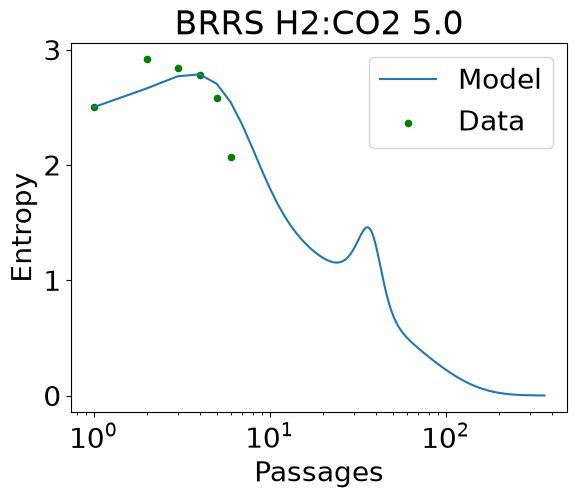

Converged to steady state after 521 passages.

--- Results for ('BRRS', 'H2:CO2', np.float64(30.0)) ---
Initial Abundance (First 5 Species): 
[0.02619896 0.10233523 0.08787643 0.00287886 0.04955027]
Steady State Abundance (First 5 Species): 
[8.e-44 8.e-44 8.e-44 8.e-44 8.e-44]


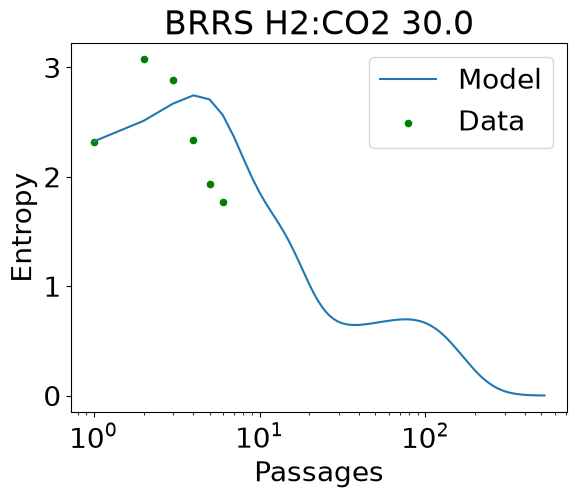

Sample condition in test key. Continuing...
Sample condition in test key. Continuing...
Converged to steady state after 340 passages.

--- Results for ('BRRS', 'H2:CO2 + TMA', np.float64(5.0)) ---
Initial Abundance (First 5 Species): 
[0.01942894 0.03751206 0.02442294 0.00599003 0.03149004]
Steady State Abundance (First 5 Species): 
[1.09489e-40 7.84727e-44 7.84727e-44 7.84727e-44 7.84727e-44]


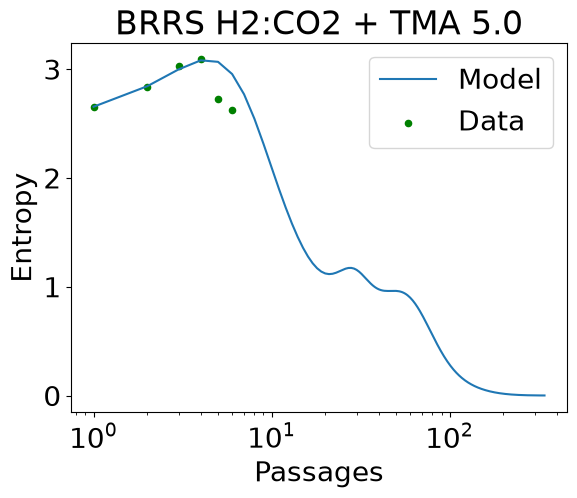

Converged to steady state after 811 passages.

--- Results for ('BRRS', 'H2:CO2 + TMA', np.float64(30.0)) ---
Initial Abundance (First 5 Species): 
[0.0146275  0.04005363 0.06140635 0.00832652 0.0314177 ]
Steady State Abundance (First 5 Species): 
[8.5e-44 8.5e-44 8.5e-44 8.5e-44 8.5e-44]


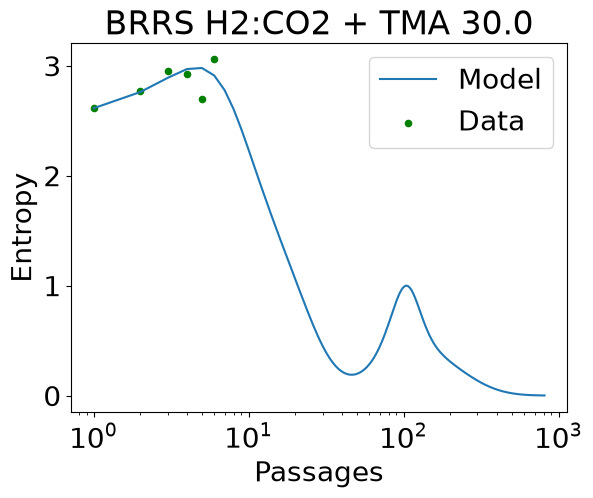

Converged to steady state after 418 passages.

--- Results for ('OSU', 'H2:CO2', np.float64(5.0)) ---
Initial Abundance (First 5 Species): 
[0.29359424 0.05420066 0.0801481  0.01838169 0.01621142]
Steady State Abundance (First 5 Species): 
[8.1e-44 8.1e-44 8.1e-44 8.1e-44 8.1e-44]


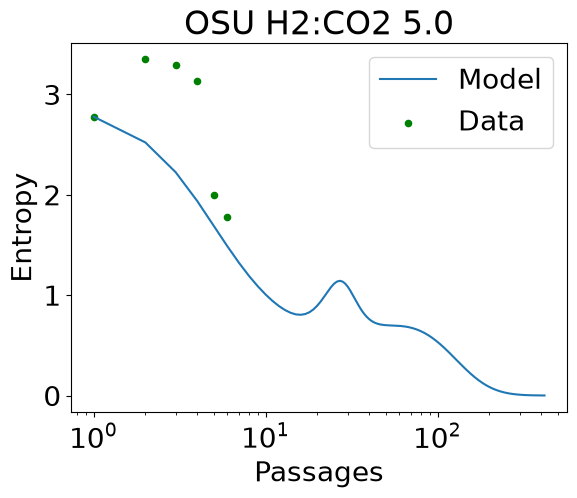

Converged to steady state after 486 passages.

--- Results for ('OSU', 'H2:CO2', np.float64(30.0)) ---
Initial Abundance (First 5 Species): 
[2.2307552e-01 1.0084505e-01 7.2090486e-05 9.6283210e-03 3.1303175e-02]
Steady State Abundance (First 5 Species): 
[8.e-44 8.e-44 8.e-44 8.e-44 8.e-44]


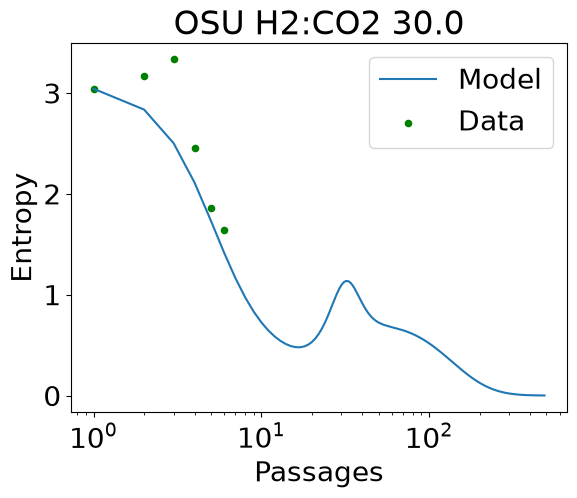

Converged to steady state after 675 passages.

--- Results for ('OSU', 'H2:CO2 + MeOH', np.float64(5.0)) ---
Initial Abundance (First 5 Species): 
[0.4289098  0.09323514 0.07494915 0.04601325 0.02612092]
Steady State Abundance (First 5 Species): 
[9.1e-44 9.1e-44 9.1e-44 9.1e-44 9.1e-44]


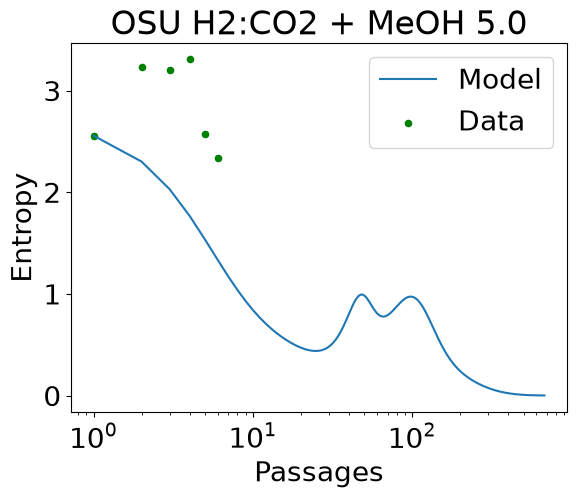

Converged to steady state after 363 passages.

--- Results for ('OSU', 'H2:CO2 + MeOH', np.float64(30.0)) ---
Initial Abundance (First 5 Species): 
[0.39475515 0.10510408 0.0406178  0.0146523  0.02810601]
Steady State Abundance (First 5 Species): 
[4.090011e-33 9.108440e-44 9.108440e-44 9.108440e-44 9.108440e-44]


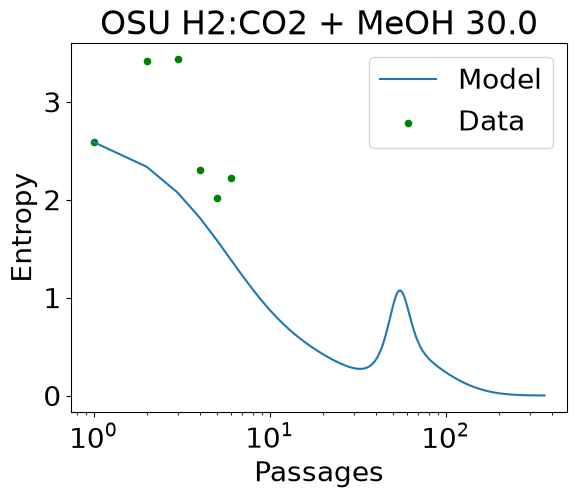

Converged to steady state after 340 passages.

--- Results for ('OSU', 'H2:CO2 + TMA', np.float64(5.0)) ---
Initial Abundance (First 5 Species): 
[0.00798515 0.0813197  0.11729817 0.01306082 0.024593  ]
Steady State Abundance (First 5 Species): 
[4.469e-41 7.847e-44 7.847e-44 7.847e-44 7.847e-44]


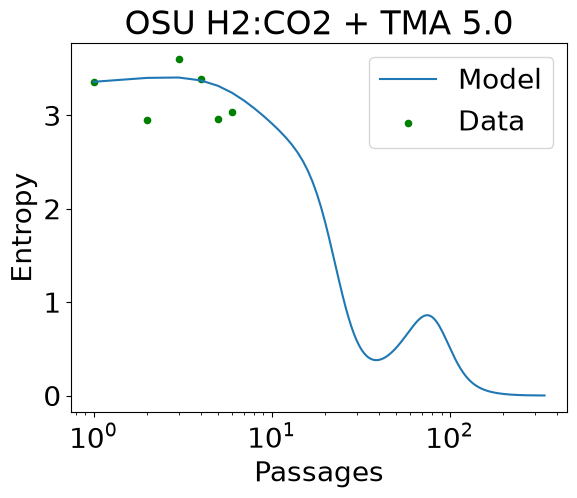

Converged to steady state after 906 passages.

--- Results for ('OSU', 'H2:CO2 + TMA', np.float64(30.0)) ---
Initial Abundance (First 5 Species): 
[0.04028717 0.07738823 0.09821084 0.00721061 0.02379265]
Steady State Abundance (First 5 Species): 
[8.5e-44 8.5e-44 8.5e-44 8.5e-44 8.5e-44]


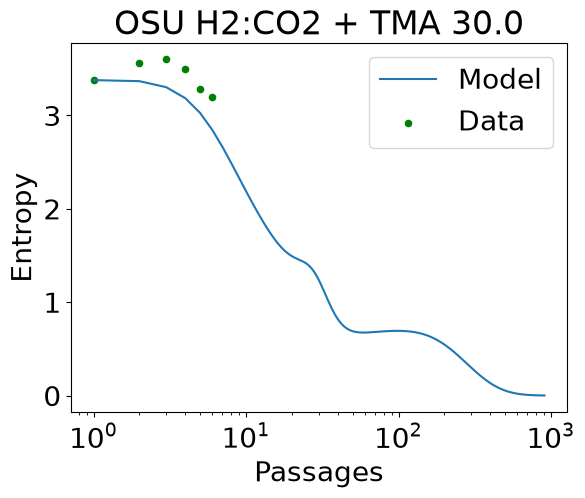

In [104]:
# =======================================================
# 4. Pick a condition and simulate
# =======================================================

for sample_condition in trajectories.keys():
    
    if sample_condition in test_keys:
        print('Sample condition in test key. Continuing...')
        continue
    
    # Let's simulate for the 5.0 psi MeOH test condition
    # sample_condition = ('OSU', 'H2:CO2 + TMA', 30.0)
    condition_idx = env_map[sample_condition]

    # Start with the T1 (first passage) relative abundance from the data
    x_0 = trajectories[sample_condition][0]
    experimental_entropy = sp.stats.entropy(trajectories[sample_condition], axis=1)
    steady_state_abundance, total_passages, entropy_list = simulate_to_steady_state(model, x_0, condition_idx)

    print(f"\n--- Results for {sample_condition} ---")
    print(f"Initial Abundance (First 5 Species): \n{x_0[:5].numpy()}")
    print(f"Steady State Abundance (First 5 Species): \n{steady_state_abundance[:5].numpy()}")

    plt.plot(np.arange(1, total_passages+2), entropy_list, label='Model')
    plt.scatter(np.arange(1, len(experimental_entropy)+1), experimental_entropy, marker='o', s=20, c='g', label='Data')
    plt.xscale('log')
    plt.ylabel('Entropy')
    plt.xlabel('Passages')
    plt.legend()
    plt.title(" ".join([str(x) for x in sample_condition]))
    plt.show()